<a href="https://colab.research.google.com/github/jvbrandao18/mestrado/blob/main/Aula_04_EDA_Process_Mining.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 4 — Exploratory Data Analysis (EDA)

## Dataset: Project Process Mining Event Log

### Objective
Perform an exploratory data analysis to identify patterns,
evaluate data quality, investigate relationships between variables,
and generate insights to support decision-making.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações de visualização
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [ ]:
df = pd.read_csv("/content/project_process_mining_event_log.csv")

df.head()

,case_id,event_id,event_sequence,activity,start_timestamp,complete_timestamp,processing_time_hours,resource,role,department,...,region,estimated_amount_brl,procurement_required,status,rework_flag,notes,source_system,waiting_time_from_previous_hours,case_duration_days,case_outcome
0,PRJ-2026-0001,PRJ-2026-0001-E01,1,Register Project Request,2026-01-26 08:00:00,2026-01-26 08:31:59,0.53,Ana,Requester,Manufacturing,...,Araucária,23300.04,True,Completed,False,NaN,PMO Portal,0.00,38.1,Completed On Time
1,PRJ-2026-0001,PRJ-2026-0001-E02,2,Initial Completeness Check,2026-01-26 16:09:19,2026-01-27 08:32:48,1.39,Lucas,PMO Analyst,Manufacturing,...,Araucária,23300.04,True,Completed,False,NaN,PMO Portal,7.62,38.1,Completed On Time
2,PRJ-2026-0001,PRJ-2026-0001-E03,3,Technical Feasibility Review,2026-01-27 08:32:48,2026-01-27 13:29:16,4.94,Paula,Engineer,Manufacturing,...,Araucária,23300.04,True,Completed,False,NaN,PMO Portal,0.00,38.1,Completed On Time
3,PRJ-2026-0001,PRJ-2026-0001-E04,4,Estimate Budget,2026-01-28 13:29:16,2026-01-28 15:44:30,2.25,Otavio,Engineer,Manufacturing,...,Araucária,23300.04,True,Completed,False,NaN,PMO Portal,24.00,38.1,Completed On Time
4,PRJ-2026-0001,PRJ-2026-0001-E05,5,Budget Approval,2026-02-02 15:44:30,2026-02-03 09:46:01,3.03,Sofia,Finance,Manufacturing,...,Araucária,23300.04,True,Completed,False,NaN,ERP,120.00,38.1,Completed On Time


In [ ]:
print("Dataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset dimensions: (23388, 22)

Column names:
['case_id', 'event_id', 'event_sequence', 'activity', 'start_timestamp', 'complete_timestamp', 'processing_time_hours', 'resource', 'role', 'department', 'project_type', 'priority', 'region', 'estimated_amount_brl', 'procurement_required', 'status', 'rework_flag', 'notes', 'source_system', 'waiting_time_from_previous_hours', 'case_duration_days', 'case_outcome']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23388 entries, 0 to 23387
Data columns (total 22 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   case_id                           23388 non-null  object 
 1   event_id                          23388 non-null  object 
 2   event_sequence                    23388 non-null  int64  
 3   activity                          23388 non-null  object 
 4   start_timestamp                   23388 non-null  object 
 5   complete_ti

In [ ]:
numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical variables:")
print(numerical_columns)

print("\nCategorical variables:")
print(categorical_columns)

Numerical variables:
['event_sequence', 'processing_time_hours', 'estimated_amount_brl', 'waiting_time_from_previous_hours', 'case_duration_days']

Categorical variables:
['case_id', 'event_id', 'activity', 'start_timestamp', 'complete_timestamp', 'resource', 'role', 'department', 'project_type', 'priority', 'region', 'procurement_required', 'status', 'rework_flag', 'notes', 'source_system', 'case_outcome']


In [ ]:
# Convert timestamp columns to datetime

df["start_timestamp"] = pd.to_datetime(
    df["start_timestamp"],
    errors="coerce"
)

df["complete_timestamp"] = pd.to_datetime(
    df["complete_timestamp"],
    errors="coerce"
)

# Check updated data types
print(df[["start_timestamp", "complete_timestamp"]].dtypes)

start_timestamp       datetime64[ns]
complete_timestamp    datetime64[ns]
dtype: object


In [ ]:
# Missing values analysis

missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

missing_values = missing_values.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_values)

,Missing Count,Missing Percentage
notes,19621,83.89
waiting_time_from_previous_hours,1331,5.69
resource,1169,5.00
processing_time_hours,1169,5.00
estimated_amount_brl,1159,4.96
priority,943,4.03
source_system,936,4.00
case_duration_days,917,3.92
role,702,3.00
project_type,698,2.98


In [ ]:
# Check duplicated records

print("Duplicated rows:", df.duplicated().sum())

print("Duplicated event IDs:", df["event_id"].duplicated().sum())

print("Unique projects:", df["case_id"].nunique())

print("Unique events:", df["event_id"].nunique())

Duplicated rows: 0
Duplicated event IDs: 0
Unique projects: 1200
Unique events: 23388


In [ ]:
# Check potentially invalid negative values

columns_to_check = [
    "processing_time_hours",
    "estimated_amount_brl",
    "waiting_time_from_previous_hours",
    "case_duration_days"
]

for col in columns_to_check:
    negative_count = (df[col] < 0).sum()

    print(f"{col}: {negative_count} negative values")

processing_time_hours: 0 negative values
estimated_amount_brl: 0 negative values
waiting_time_from_previous_hours: 0 negative values
case_duration_days: 0 negative values


In [ ]:
# Numerical variables for outlier analysis
numerical_columns = [
    "processing_time_hours",
    "estimated_amount_brl",
    "waiting_time_from_previous_hours",
    "case_duration_days"
]

# One record per project for case duration analysis
project_df = df.drop_duplicates(subset="case_id").copy()

for col in numerical_columns:

    # Project duration should be analyzed at project level
    data = (
        project_df[col].dropna()
        if col == "case_duration_days"
        else df[col].dropna()
    )

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data < lower_bound) |
        (data > upper_bound)
    ]

    print(f"\nVariable: {col}")
    print(f"Q1: {Q1:.2f}")
    print(f"Q3: {Q3:.2f}")
    print(f"IQR: {IQR:.2f}")
    print(f"Lower Bound: {lower_bound:.2f}")
    print(f"Upper Bound: {upper_bound:.2f}")
    print(f"Outliers: {len(outliers)}")
    print(f"Outlier Percentage: {len(outliers)/len(data)*100:.2f}%")


Variable: processing_time_hours
Q1: 0.69
Q3: 2.49
IQR: 1.80
Lower Bound: -2.01
Upper Bound: 5.19
Outliers: 1715
Outlier Percentage: 7.72%

Variable: estimated_amount_brl
Q1: 21858.64
Q3: 65781.39
IQR: 43922.75
Lower Bound: -44025.49
Upper Bound: 131665.52
Outliers: 1265
Outlier Percentage: 5.69%

Variable: waiting_time_from_previous_hours
Q1: 7.93
Q3: 72.00
IQR: 64.07
Lower Bound: -88.17
Upper Bound: 168.10
Outliers: 955
Outlier Percentage: 4.33%

Variable: case_duration_days
Q1: 46.30
Q3: 67.05
IQR: 20.75
Lower Bound: 15.16
Upper Bound: 98.18
Outliers: 45
Outlier Percentage: 3.91%


In [ ]:
# Check whether project duration is consistent within each case

duration_variations = (
    df.groupby("case_id")["case_duration_days"]
    .nunique(dropna=True)
)

print(
    "Projects with conflicting durations:",
    (duration_variations > 1).sum()
)

print(
    "Projects without any duration:",
    (duration_variations == 0).sum()
)

Projects with conflicting durations: 0
Projects without any duration: 48


### Data Cleaning and Treatment Decisions

The dataset contains 23,388 events distributed across 1,200 projects.

No duplicated records, duplicated event IDs, or negative values
were identified in the numerical variables examined.

Missing values were identified in several columns.
The notes column has the highest missing percentage (83.89%),
but it was retained because it may contain optional information.

Outliers were identified using the Interquartile Range (IQR) method.

These observations were retained because extreme processing times,
waiting times, project durations, and financial amounts may represent
legitimate business situations rather than data errors.

For project-level analysis, one observation per project will be used
to avoid giving greater statistical weight to projects with more events.

Among the 1,200 projects, 48 have no recorded duration.
These projects will be excluded only from analyses requiring
case_duration_days.

This approach preserves potentially meaningful information
while avoiding unnecessary data manipulation.

In [ ]:
# Create project-level dataset
project_df = (
    df.groupby("case_id", as_index=False)
    .first()
)

# Select projects with valid duration
duration_data = project_df["case_duration_days"].dropna()

print("Total projects:", len(project_df))
print("Projects with valid duration:", len(duration_data))
print("Projects without duration:", duration_data.size and len(project_df) - len(duration_data))

Total projects: 1200
Projects with valid duration: 1152
Projects without duration: 48


In [ ]:
# Descriptive statistics for project duration

statistics = pd.DataFrame({
    "Statistic": [
        "Count",
        "Mean",
        "Median",
        "Standard Deviation",
        "Minimum",
        "Q1 (25%)",
        "Q3 (75%)",
        "Maximum"
    ],
    "Value": [
        duration_data.count(),
        duration_data.mean(),
        duration_data.median(),
        duration_data.std(),
        duration_data.min(),
        duration_data.quantile(0.25),
        duration_data.quantile(0.75),
        duration_data.max()
    ]
})

display(statistics.round(2))

,Statistic,Value
0,Count,1152.00
1,Mean,55.28
2,Median,56.81
3,Standard Deviation,17.56
4,Minimum,5.19
5,Q1 (25%),46.30
6,Q3 (75%),67.05
7,Maximum,104.85


### Univariate Analysis — Project Duration

The variable `case_duration_days` was selected to investigate
the distribution of project completion times.

The analysis includes 1,152 projects with valid duration records.

The average project duration is 55.28 days, while the median
is 56.81 days.

The standard deviation is 17.56 days, indicating variability
in project completion times.

The interquartile range extends from 46.30 to 67.05 days,
meaning that the middle 50% of projects fall within this interval.

A histogram is used to examine the distribution and identify
potentially unusual project durations.

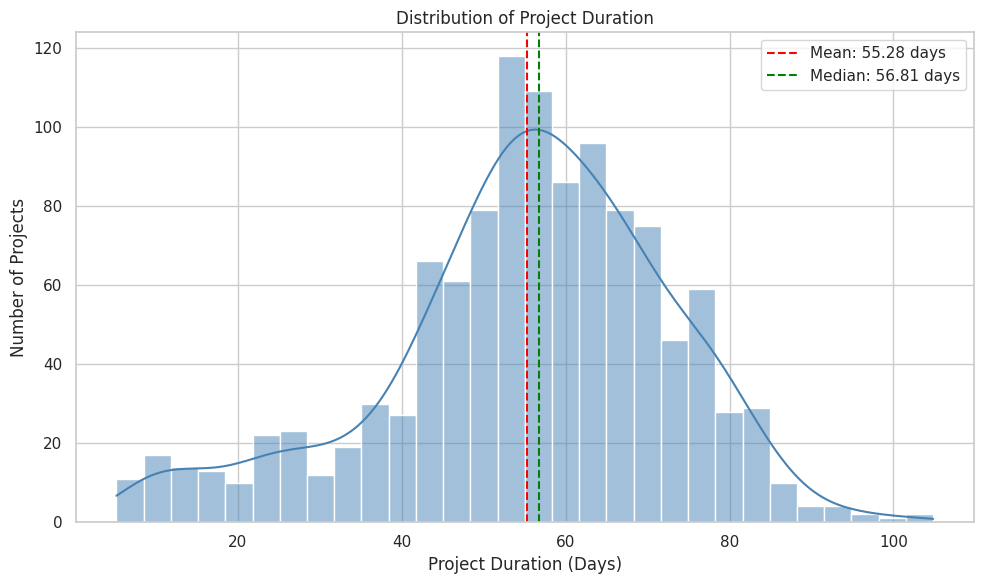

In [ ]:
# Histogram of project duration

plt.figure(figsize=(10, 6))

sns.histplot(
    duration_data,
    bins=30,
    kde=True,
    color="steelblue"
)

# Mean and median reference lines
plt.axvline(
    duration_data.mean(),
    color="red",
    linestyle="--",
    label=f"Mean: {duration_data.mean():.2f} days"
)

plt.axvline(
    duration_data.median(),
    color="green",
    linestyle="--",
    label=f"Median: {duration_data.median():.2f} days"
)

plt.title("Distribution of Project Duration")
plt.xlabel("Project Duration (Days)")
plt.ylabel("Number of Projects")

plt.legend()
plt.tight_layout()
plt.show()

### Histogram Interpretation

The histogram shows that most projects have durations
concentrated between approximately 45 and 75 days,
with a peak around 55–60 days.

The mean (55.28 days) is slightly lower than the median
(56.81 days), suggesting a mild left-skewed distribution.

A smaller group of projects has considerably shorter
durations, particularly between 5 and 30 days.

Some projects also exhibit unusually long durations,
exceeding 100 days.

These observations may reflect differences in project
complexity, priority, or other operational characteristics.

Further analysis is required to determine whether these
differences are associated with specific project groups.

In [ ]:
# Calculate IQR boundaries

Q1 = duration_data.quantile(0.25)
Q3 = duration_data.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Create a temporary dataset without IQR outliers

duration_without_outliers = duration_data[
    (duration_data >= lower_bound) &
    (duration_data <= upper_bound)
]

# Compare descriptive statistics

comparison = pd.DataFrame({
    "Original Data": duration_data.describe(),
    "Without Outliers": duration_without_outliers.describe()
})

comparison["Difference"] = (
    comparison["Without Outliers"] -
    comparison["Original Data"]
)

display(comparison.round(2))

,Original Data,Without Outliers,Difference
count,1152.00,1107.00,-45.00
mean,55.28,56.85,1.57
std,17.56,15.36,-2.21
min,5.19,16.02,10.83
25%,46.30,47.94,1.64
50%,56.81,57.06,0.25
75%,67.05,67.16,0.11
max,104.85,96.68,-8.17


### Impact of Outlier Treatment

Using the IQR method, 45 projects (3.91%) were identified
as potential outliers.

After temporarily excluding these observations, the mean
project duration increased from 55.28 to 56.85 days,
while the median changed only slightly, from 56.81 to
57.06 days.

The standard deviation decreased from 17.56 to 15.36
days, indicating lower variability after excluding
extreme observations.

The increase in the mean suggests that unusually short
projects have a stronger influence on the average than
unusually long projects.

However, these extreme observations may represent valid
business situations.

Therefore, the original observations will be retained
for subsequent analyses, while missing values will be
handled according to the variables required.

In [ ]:
# Check available priority categories

print("Priority categories:")
print(project_df["priority"].value_counts(dropna=False))

# Calculate descriptive statistics by priority

priority_stats = (
    project_df
    .groupby("priority")["case_duration_days"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
    .sort_values("median", ascending=False)
)

display(priority_stats)

Priority categories:
priority
Medium      552
High        286
Low         214
Critical    100
None         48
Name: count, dtype: int64


,count,mean,median,std,min,max
priority,,,,,,
Critical,96,57.14,59.03,16.50,14.07,86.80
Low,205,56.01,57.10,19.35,7.02,104.85
High,271,55.33,56.15,15.60,6.03,89.90
Medium,533,54.60,56.02,18.02,5.19,96.68


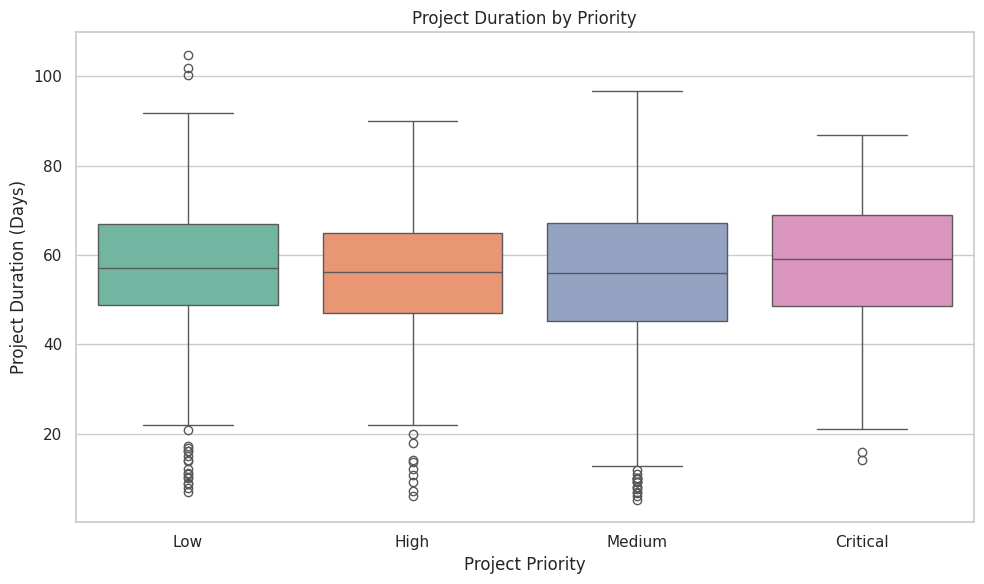

In [ ]:
# Boxplot: Project Duration by Priority

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=project_df,
    x="priority",
    y="case_duration_days",
    hue="priority",
    palette="Set2",
    legend=False
)

plt.title("Project Duration by Priority")
plt.xlabel("Project Priority")
plt.ylabel("Project Duration (Days)")

plt.tight_layout()
plt.show()

### Boxplot 1 — Project Duration by Priority

The boxplot compares project duration across four priority
categories: Low, Medium, High, and Critical.

Critical projects have the highest median duration
(59.03 days), while Medium-priority projects have the
lowest median (56.02 days).

The difference between these groups is approximately
3 days, indicating relatively similar completion times.

Low-priority projects show the highest standard deviation
(19.35 days), suggesting greater variability in their
completion times.

Several outliers are observed, particularly among
Low-, Medium-, and High-priority projects.

Overall, the distributions overlap considerably,
suggesting that priority alone may not be a strong
indicator of project duration.

Further investigation is needed to understand whether
project complexity, type, or other characteristics
contribute to these differences.

In [ ]:
# Check available project types

print("Project types:")
print(project_df["project_type"].value_counts(dropna=False))

# Descriptive statistics by project type

project_type_stats = (
    project_df
    .groupby("project_type")["case_duration_days"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
    .sort_values("median", ascending=False)
)

display(project_type_stats)

Project types:
project_type
Sustainability         213
New Product Support    204
Quality Improvement    193
Maintenance Upgrade    192
Process Improvement    191
Automation             171
None                    36
Name: count, dtype: int64


,count,mean,median,std,min,max
project_type,,,,,,
New Product Support,196,56.37,60.07,17.84,6.03,91.88
Automation,163,57.96,58.65,18.18,5.19,101.86
Quality Improvement,183,56.09,57.10,17.77,6.74,104.85
Process Improvement,185,54.84,56.77,18.14,6.03,100.24
Maintenance Upgrade,186,53.85,54.97,16.71,6.91,94.72
Sustainability,206,53.14,54.88,16.55,7.70,84.95


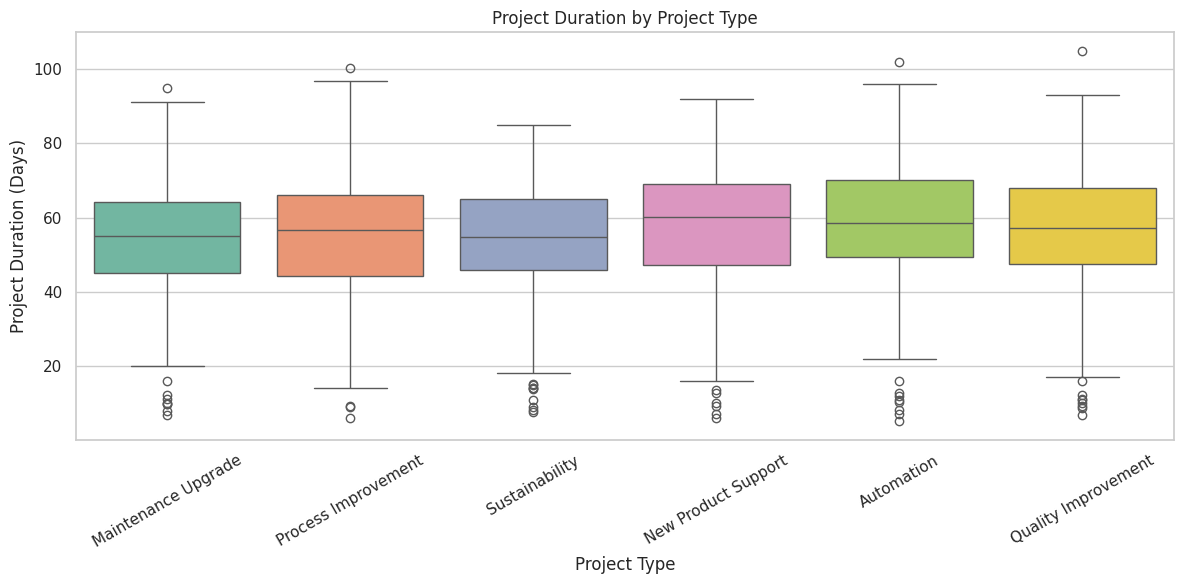

In [ ]:
# Boxplot: Project Duration by Project Type

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=project_df,
    x="project_type",
    y="case_duration_days",
    hue="project_type",
    palette="Set2",
    legend=False
)

plt.title("Project Duration by Project Type")
plt.xlabel("Project Type")
plt.ylabel("Project Duration (Days)")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

### Boxplot 2 — Project Duration by Project Type

The boxplot compares project duration across six
different project types.

New Product Support has the highest median duration
(60.07 days), while Sustainability has the lowest
median (54.88 days).

The difference between these categories is approximately
5.19 days.

Automation projects show the highest standard deviation
(18.18 days), indicating slightly greater variability
in completion times.

Sustainability projects have the lowest standard
deviation (16.55 days), suggesting more consistent
durations.

Several outliers are observed across the categories,
including projects lasting more than 100 days.

Although differences exist between project types,
their distributions overlap considerably.

These findings suggest that project type may be
associated with completion time, but additional
analysis is necessary to investigate this relationship.

A total of 33 projects with valid durations were excluded
from this comparison because their project type was missing.

In [ ]:
# Check procurement requirements

print("Procurement Required:")
print(
    project_df["procurement_required"]
    .value_counts(dropna=False)
)

# Descriptive statistics by procurement requirement

procurement_stats = (
    project_df
    .groupby("procurement_required")["case_duration_days"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

display(procurement_stats)

Procurement Required:
procurement_required
True     1102
False      98
Name: count, dtype: int64


,count,mean,median,std,min,max
procurement_required,,,,,,
False,94,28.27,27.82,8.79,6.03,51.14
True,1058,57.68,58.02,16.08,5.19,104.85


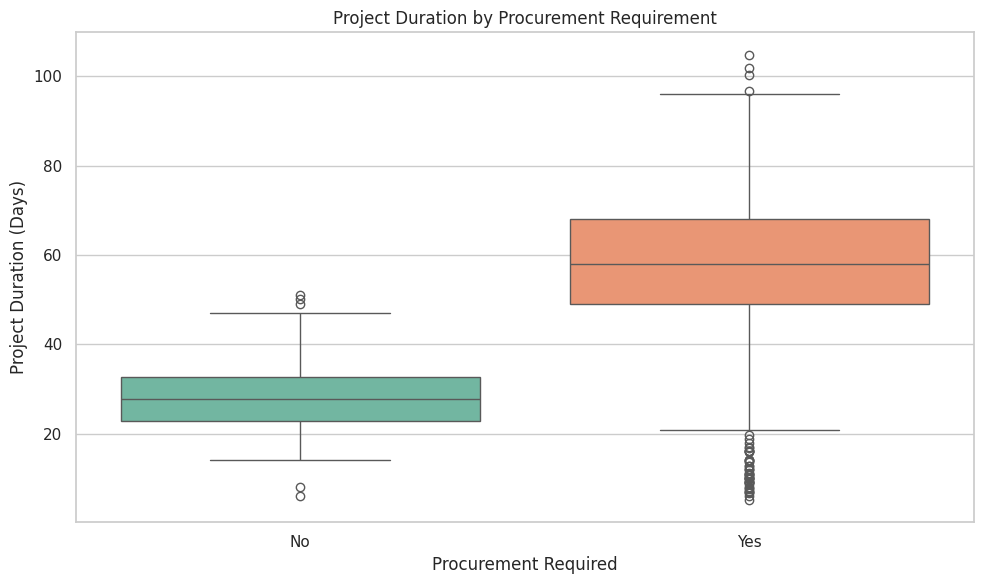

In [ ]:
# Boxplot: Project Duration by Procurement Requirement

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=project_df,
    x="procurement_required",
    y="case_duration_days",
    hue="procurement_required",
    palette="Set2",
    legend=False
)

plt.title("Project Duration by Procurement Requirement")
plt.xlabel("Procurement Required")
plt.ylabel("Project Duration (Days)")

plt.xticks(
    ticks=[0, 1],
    labels=["No", "Yes"]
)

plt.tight_layout()
plt.show()

### Boxplot 3 — Project Duration by Procurement Requirement

The boxplot compares project durations based on whether
procurement activities are required.

Projects requiring procurement have a median duration
of 58.02 days, compared to 27.82 days for projects
without procurement.

This represents a difference of 30.20 days, with
procurement-related projects having approximately
2.09 times the median duration.

Projects requiring procurement also show greater
absolute variability, with a standard deviation of
16.08 days compared to 8.79 days.

Several outliers are observed, particularly among
projects requiring procurement.

This is the largest difference in median project
duration observed across the three comparative analyses.

However, these findings demonstrate an association,
not a causal relationship.

Other factors, such as project complexity, budget,
and operational requirements, may influence duration.

The groups are also imbalanced, with 1,058 projects
requiring procurement and 94 not requiring procurement
among projects with valid duration records.

In [ ]:
# Prepare data for correlation analysis

correlation_data = project_df[
    [
        "case_id",
        "estimated_amount_brl",
        "case_duration_days",
        "procurement_required"
    ]
].dropna(
    subset=["estimated_amount_brl", "case_duration_days"]
)

print("Projects available for analysis:", len(correlation_data))

# Calculate Pearson correlation

correlation = correlation_data[
    "estimated_amount_brl"
].corr(
    correlation_data["case_duration_days"]
)

print(f"Pearson correlation: {correlation:.4f}")

Projects available for analysis: 1099
Pearson correlation: 0.1722


## 4. Relationship Analysis and Hypothesis Testing

### Research Hypothesis

Projects with higher estimated budgets tend to have
longer completion times.

The relationship between estimated project budget
(`estimated_amount_brl`) and project duration
(`case_duration_days`) will be investigated using
a scatter plot and Pearson correlation coefficient.

Each observation represents one project.

Procurement requirements will also be represented
in the scatter plot to investigate potential
differences between project groups.

The analysis aims to determine whether the available
evidence supports the proposed hypothesis.

Correlation will be interpreted as an association,
rather than evidence of causation.

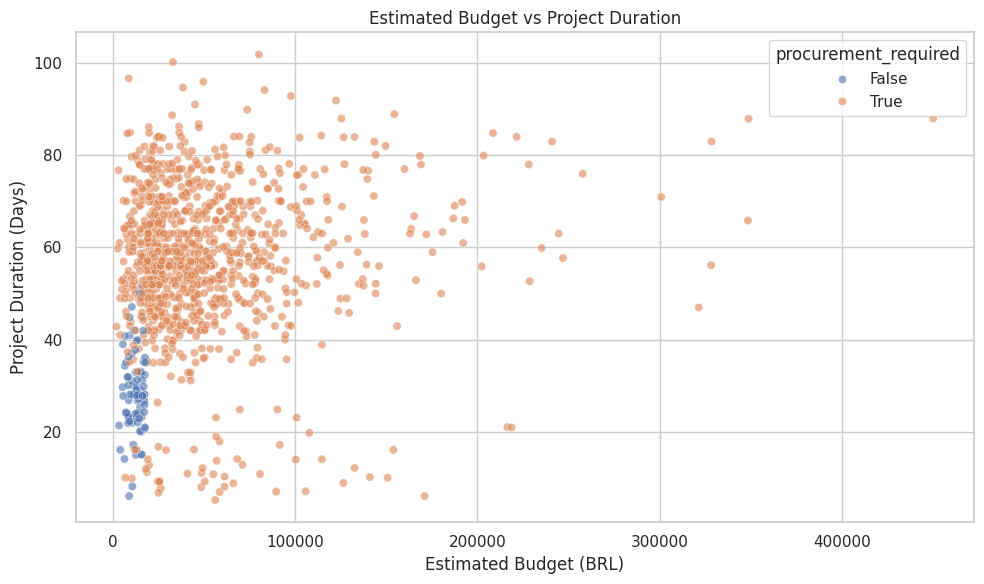

In [ ]:
# Scatter Plot: Estimated Budget vs Project Duration

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=correlation_data,
    x="estimated_amount_brl",
    y="case_duration_days",
    hue="procurement_required",
    alpha=0.6
)

plt.title("Estimated Budget vs Project Duration")

plt.xlabel("Estimated Budget (BRL)")
plt.ylabel("Project Duration (Days)")

plt.tight_layout()
plt.show()

### Scatter Plot Interpretation

The scatter plot investigates the relationship between
estimated project budget and project duration.

A total of 1,099 projects were included in the analysis.

The Pearson correlation coefficient was 0.1722,
indicating a weak positive linear relationship.

Although higher budgets are associated with slightly
longer project durations, the relationship is weak.

The coefficient of determination (R²) is approximately
0.0297, suggesting that estimated budget alone explains
only about 3% of the observed variation in project duration
in a simple linear regression model.

Projects with similar budgets exhibit considerably
different completion times.

The visualization also suggests that procurement
requirements may be associated with project duration.

Overall, the results provide limited support for the
initial hypothesis.

Estimated budget alone does not appear to be a strong
linear predictor of project completion time.

In [ ]:
# Correlation between budget and duration by procurement group

for procurement, group in correlation_data.groupby(
    "procurement_required"
):
    correlation = group[
        "estimated_amount_brl"
    ].corr(
        group["case_duration_days"]
    )

    print(f"\nProcurement Required: {procurement}")
    print(f"Projects: {len(group)}")
    print(f"Pearson Correlation: {correlation:.4f}")


Procurement Required: False
Projects: 87
Pearson Correlation: 0.1022

Procurement Required: True
Projects: 1012
Pearson Correlation: 0.0758


In [ ]:
# Create project-level metrics

project_metrics = (
    df.groupby("case_id")
    .agg(
        estimated_amount_brl=(
            "estimated_amount_brl", "first"
        ),
        case_duration_days=(
            "case_duration_days", "first"
        ),
        total_processing_hours=(
            "processing_time_hours",
            lambda x: x.sum(min_count=1)
        ),
        total_waiting_hours=(
            "waiting_time_from_previous_hours",
            lambda x: x.sum(min_count=1)
        ),
        number_of_events=(
            "event_id", "count"
        )
    )
    .reset_index()
)

print("Project-level dataset:", project_metrics.shape)

display(project_metrics.head())

Project-level dataset: (1200, 6)


,case_id,estimated_amount_brl,case_duration_days,total_processing_hours,total_waiting_hours,number_of_events
0,PRJ-2026-0001,23300.04,38.10,34.45,713.59,18
1,PRJ-2026-0002,21852.30,50.12,40.86,1131.92,22
2,PRJ-2026-0003,23948.44,50.97,33.00,1031.29,18
3,PRJ-2026-0004,NaN,57.78,35.02,1315.72,21
4,PRJ-2026-0005,71857.42,67.20,35.32,1513.25,23


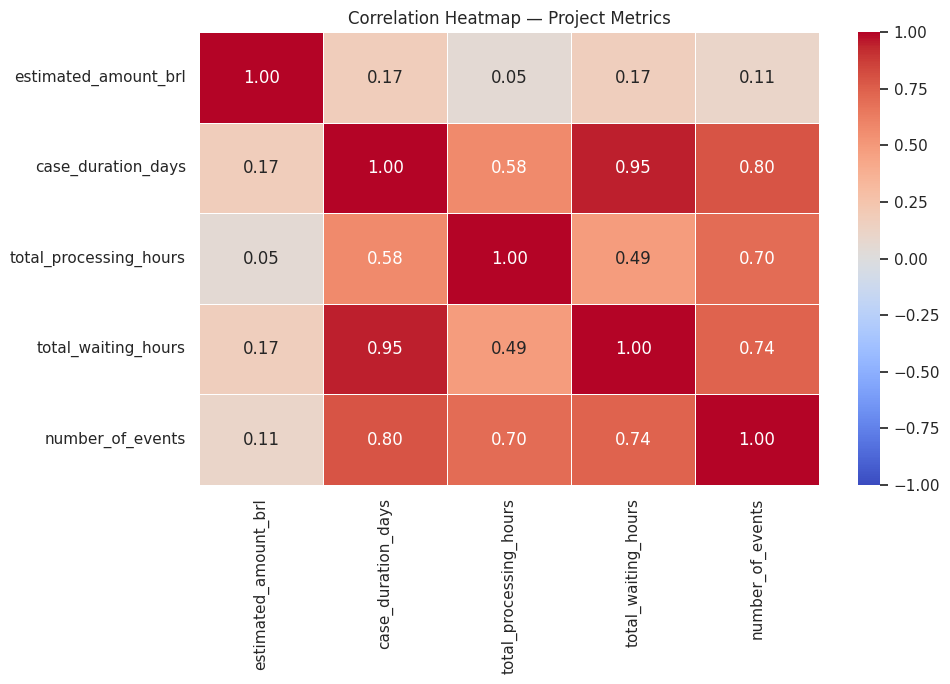

In [ ]:
# Calculate correlation matrix

correlation_matrix = project_metrics[
    [
        "estimated_amount_brl",
        "case_duration_days",
        "total_processing_hours",
        "total_waiting_hours",
        "number_of_events"
    ]
].corr(method="pearson")

# Create heatmap

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Correlation Heatmap — Project Metrics")

plt.tight_layout()
plt.show()

### Correlation Heatmap Interpretation

The correlation heatmap reveals several relationships
between project-level numerical variables.

The strongest positive correlation was identified
between total waiting time and project duration
(r = 0.95).

This indicates that projects with longer accumulated
waiting times tend to have longer completion times.

However, waiting time is also a component of total
project duration, which may partly explain this
strong correlation.

The number of events also shows a strong positive
correlation with project duration (r = 0.80).

Total processing time presents a moderate positive
correlation with project duration (r = 0.58).

In contrast, estimated budget shows a weak positive
correlation with duration (r = 0.17).

When projects were separated by procurement requirement,
the correlations between budget and duration decreased
to 0.10 and 0.08, respectively.

These results suggest that the overall association
between budget and duration may partly reflect
differences between procurement groups.

No negative correlations were identified among
the selected numerical variables.

Overall, the findings suggest that operational
characteristics, particularly accumulated waiting
time and the number of events, are more strongly
associated with project duration than estimated budget.

These correlations do not establish causal relationships.

## 5. Final Conclusions and Recommendations

### 5.1. Dataset Overview

The dataset contains 23,388 events associated with
1,200 distinct projects.

Each event represents an activity performed during
a project's lifecycle.

The analysis focused on project duration, estimated
budget, priority, project type, procurement requirements,
processing time, and waiting time.

### 5.2. Data Quality and Treatment

No duplicated events or negative numerical values
were identified.

Missing values were detected in several variables,
including project duration and estimated budget.

A total of 48 projects had no recorded duration.

Potential outliers were identified using the
Interquartile Range (IQR) method.

For project duration, 45 observations were classified
as potential outliers.

Removing these observations temporarily increased
the mean duration from 55.28 to 56.85 days and
reduced the standard deviation from 17.56 to
15.36 days.

However, the original observations were retained
because extreme durations may represent legitimate
business situations.

### 5.3. Main Findings

The average project duration was 55.28 days,
with a median of 56.81 days.

Comparative analyses revealed relatively small
differences in project duration across priority
levels and project types.

The most substantial difference was observed
between projects with and without procurement
requirements.

Projects requiring procurement had a median
duration of 58.02 days, compared to 27.82 days
for projects without procurement.

This represents a difference of approximately
30 days.

The correlation analysis revealed that total
waiting time had the strongest positive
correlation with project duration (r = 0.95).

The number of events also showed a strong
positive correlation (r = 0.80).

These relationships suggest that operational
characteristics are important when investigating
project completion times.

### 5.4. Hypothesis Evaluation

The initial hypothesis proposed that projects
with higher estimated budgets would have
longer completion times.

The Pearson correlation coefficient between
estimated budget and project duration was 0.1722.

This indicates a weak positive linear relationship.

Separate analyses of projects with and without
procurement requirements produced even weaker
correlations.

Therefore, the hypothesis received only
limited support.

Estimated budget alone does not appear to be
a strong linear predictor of project duration.

### 5.5. Recommendations

Based on the exploratory findings, organizations
should prioritize further investigation of
operational waiting times and procurement-related
activities.

Recommended actions include:

1. Identify activities responsible for the
   longest waiting periods.

2. Investigate procurement approval workflows
   and potential administrative bottlenecks.

3. Examine whether projects with more events
   experience unnecessary process complexity
   or rework.

4. Monitor project duration using indicators
   related to waiting time, processing time,
   and procurement requirements.

5. Conduct additional analyses to control
   for project complexity, type, and budget
   before drawing causal conclusions.

### 5.6. Final Considerations

The exploratory analysis identified meaningful
associations between project duration and
operational characteristics.

Procurement requirements, accumulated waiting
time, and the number of events emerged as
relevant factors for further investigation.

However, the results are observational,
and correlations should not be interpreted
as evidence of causation.

Further process mining analysis could help
identify specific activities and bottlenecks
that contribute to longer project durations.

In [ ]:
# Check consistency of project-level attributes

project_attributes = [
    "priority",
    "project_type",
    "department",
    "region",
    "estimated_amount_brl",
    "procurement_required",
    "case_duration_days",
    "case_outcome"
]

consistency_results = []

for col in project_attributes:

    # Count distinct non-null values within each project
    unique_values = df.groupby("case_id")[col].nunique(
        dropna=True
    )

    # Projects containing more than one distinct value
    inconsistent_projects = (unique_values > 1).sum()

    # Projects with no valid value
    missing_projects = (unique_values == 0).sum()

    consistency_results.append({
        "Variable": col,
        "Inconsistent Projects": inconsistent_projects,
        "Projects Without Values": missing_projects
    })

consistency_df = pd.DataFrame(consistency_results)

display(consistency_df)

,Variable,Inconsistent Projects,Projects Without Values
0,priority,0,48
1,project_type,0,36
2,department,0,0
3,region,0,36
4,estimated_amount_brl,0,60
5,procurement_required,0,0
6,case_duration_days,0,48
7,case_outcome,0,0


In [ ]:
# Check projects containing both missing and valid values

mixed_missing_results = []

for col in project_attributes:

    grouped = df.groupby("case_id")[col]

    has_missing = grouped.apply(lambda x: x.isna().any())
    has_valid = grouped.apply(lambda x: x.notna().any())

    mixed_projects = (has_missing & has_valid).sum()

    mixed_missing_results.append({
        "Variable": col,
        "Projects With Mixed Missing Values": mixed_projects
    })

display(pd.DataFrame(mixed_missing_results))

,Variable,Projects With Mixed Missing Values
0,priority,0
1,project_type,0
2,department,0
3,region,0
4,estimated_amount_brl,0
5,procurement_required,0
6,case_duration_days,0
7,case_outcome,0


### Project-Level Data Consistency Validation

An additional consistency check was performed to verify
whether project-level attributes remained consistent
across multiple events belonging to the same project.

Eight variables were evaluated:

- Priority
- Project type
- Department
- Region
- Estimated budget
- Procurement requirement
- Project duration
- Project outcome

The analysis identified no conflicting values within
any of the 1,200 projects for these attributes.

Additionally, no projects contained a mixture of
missing and non-missing values within the same
attribute.

Missing information was identified at the project level,
including 48 projects without recorded duration,
60 without estimated budget, and 36 without project type.

These findings support the use of a project-level
dataset containing one observation per project
for the selected attributes.

Therefore, no additional corrections were required
for the analyses previously performed.